In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("customer_churn_sample.csv")
print(df.shape)
display(df.head())
print(df.dtypes)
print("Missing values:\n", df.isna().sum())

(15, 11)


,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes


CustomerID           object
Gender               object
Age                   int64
TenureMonths          int64
SubscriptionType     object
MonthlyCharges      float64
TotalCharges        float64
ContractType         object
SupportTickets        int64
PaymentMethod        object
Churn                object
dtype: object
Missing values:
 CustomerID          0
Gender              0
Age                 0
TenureMonths        0
SubscriptionType    0
MonthlyCharges      0
TotalCharges        0
ContractType        0
SupportTickets      0
PaymentMethod       0
Churn               0
dtype: int64


In [11]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate CustomerIDs:", df["CustomerID"].duplicated().sum())

Duplicate rows: 0
Duplicate CustomerIDs: 0


In [2]:
num_cols = ["Age", "TenureMonths", "MonthlyCharges", "TotalCharges", "SupportTickets"]
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    out = df[(df[c] < low) | (df[c] > high)]
    print(f"{c}: {len(out)} outliers (range {low:.1f} to {high:.1f})")


Age: 0 outliers (range 4.5 to 72.5)
TenureMonths: 0 outliers (range -23.0 to 57.0)
MonthlyCharges: 0 outliers (range -47.5 to 212.5)
TotalCharges: 0 outliers (range -3689.8 to 7349.5)
SupportTickets: 0 outliers (range -3.5 to 8.5)


In [3]:
clean = df.copy()

# Standardise text columns
for c in ["Gender", "SubscriptionType", "ContractType", "PaymentMethod", "Churn"]:
    clean[c] = clean[c].str.strip().str.title()

# Churn as 0/1 for analysis
clean["ChurnFlag"] = (clean["Churn"] == "Yes").astype(int)

# Validation checks
assert clean["CustomerID"].is_unique
assert clean.isna().sum().sum() == 0
assert clean["Age"].between(18, 100).all()
assert (clean["MonthlyCharges"] > 0).all()
assert (clean["TenureMonths"] >= 0).all()

# Consistency: TotalCharges should be about Monthly x Tenure
diff = (clean["TotalCharges"] - clean["MonthlyCharges"] * clean["TenureMonths"]).abs()
print("Rows where TotalCharges doesn't match Monthly x Tenure:", (diff > 1).sum())
print("All validation checks passed")

clean.to_csv("customer_churn_clean.csv", index=False)

Rows where TotalCharges doesn't match Monthly x Tenure: 0
All validation checks passed


In [8]:
display(clean[num_cols].describe().round(2))
print("Overall churn rate:", round(clean["ChurnFlag"].mean()*100, 1), "%")

for c in ["ContractType", "SubscriptionType", "PaymentMethod", "Gender"]:
    print(f"\nChurn rate by {c}")
    print((clean.groupby(c)["ChurnFlag"].mean()*100).round(1))

print(clean.groupby("Churn")[["Age", "TenureMonths", "MonthlyCharges", "SupportTickets"]].mean().round(1))

,Age,TenureMonths,MonthlyCharges,TotalCharges,SupportTickets
count,15.00,15.00,15.00,15.00,15.00
mean,39.07,18.80,84.66,2088.48,2.53
std,11.39,14.33,42.74,2407.37,1.92
min,23.00,2.00,49.99,99.98,0.00
25%,30.00,7.00,49.99,449.91,1.00
50%,38.00,15.00,79.99,1099.78,2.00
75%,47.00,27.00,114.99,3209.73,4.00
max,60.00,48.00,149.99,7199.52,6.00


Overall churn rate: 46.7 %

Churn rate by ContractType
ContractType
Month-To-Month    100.0
One Year            0.0
Two Year            0.0
Name: ChurnFlag, dtype: float64

Churn rate by SubscriptionType
SubscriptionType
Basic         71.4
Enterprise     0.0
Pro           50.0
Name: ChurnFlag, dtype: float64

Churn rate by PaymentMethod
PaymentMethod
Bank Transfer      0.0
Credit Card       33.3
Debit Card       100.0
Upi               75.0
Name: ChurnFlag, dtype: float64

Churn rate by Gender
Gender
Female    50.0
Male      42.9
Name: ChurnFlag, dtype: float64
        Age  TenureMonths  MonthlyCharges  SupportTickets
Churn                                                    
No     46.6          29.1           107.5             1.0
Yes    30.4           7.0            58.6             4.3


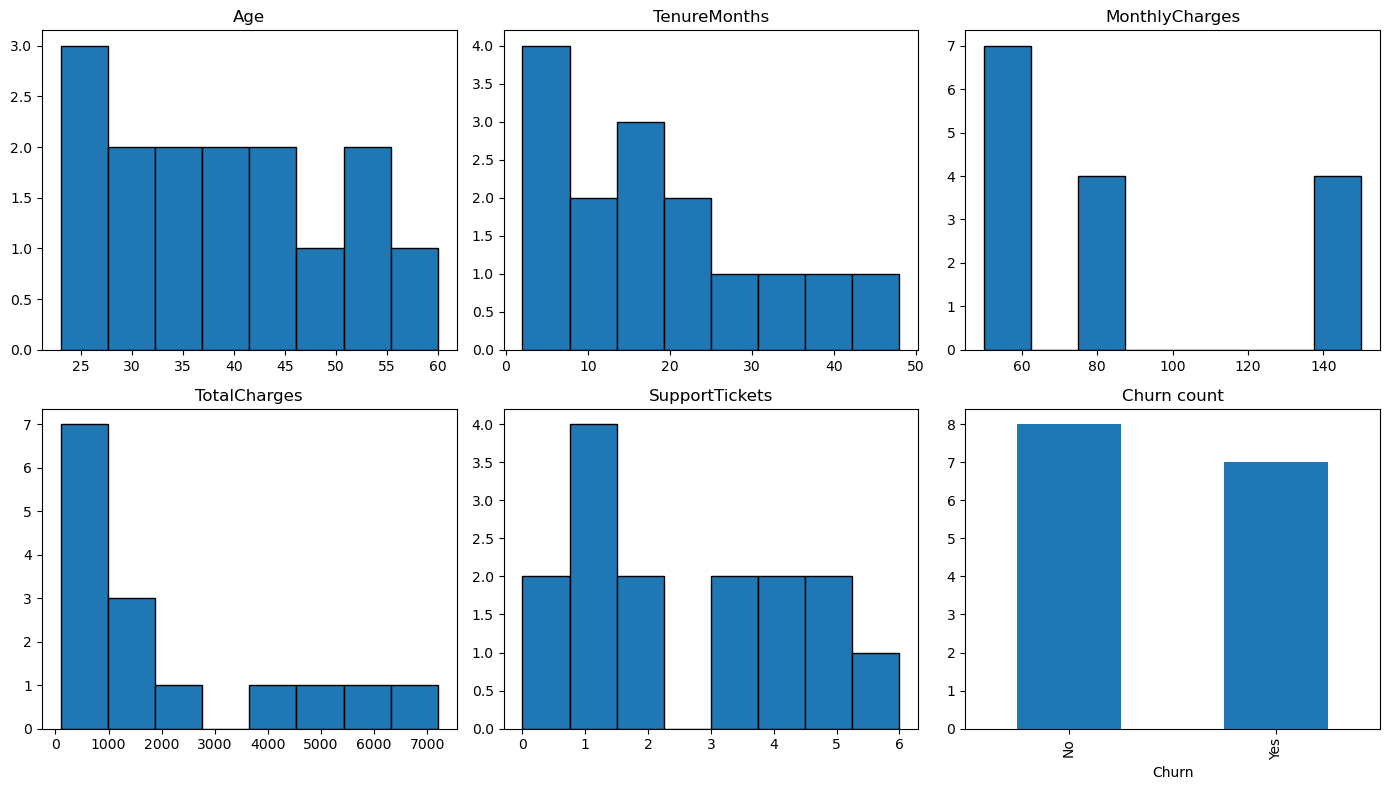

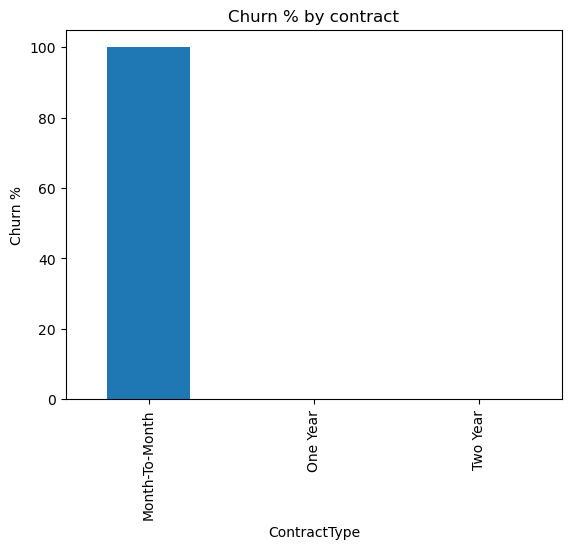

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.flat, num_cols):
    ax.hist(clean[c], bins=8, edgecolor="black")
    ax.set_title(c)
clean["Churn"].value_counts().plot(kind="bar", ax=axes.flat[5], title="Churn count")
plt.tight_layout()
plt.savefig("distributions.png")
plt.show()

(clean.groupby("ContractType")["ChurnFlag"].mean()*100).plot(kind="bar", title="Churn % by contract")
plt.ylabel("Churn %")
plt.show()

In [9]:
dictionary = pd.DataFrame({
    "Column": ["CustomerID","Gender","Age","TenureMonths","SubscriptionType",
               "MonthlyCharges","TotalCharges","ContractType","SupportTickets",
               "PaymentMethod","Churn","ChurnFlag"],
    "Description": ["Unique customer ID","Customer gender","Age in years",
                    "Months as a customer","Plan: Basic/Pro/Enterprise",
                    "Monthly fee","Total billed to date","Contract length",
                    "Number of support tickets","Payment method",
                    "Left the service (Yes/No)","1 if churned, else 0 (added by me)"]})
dictionary.to_csv("data_dictionary.csv", index=False)

no missing values or duplicates found.
then standardised text columns and added ChurnFlag colunm(1=churned).
validation checks passed.
overall churn rate:46.7%.
basic plan churns most 71.4% while enterprise had 0%.
dataset is small so patterns are indicative only.
